# E-Commerce Customer Purchase Behaviour Analysis and Prediction (Tasks 1-8)

> **Note:** The dataset is **synthetic** (simulated in this notebook with 20,000 clean customer records), not real customer data.

## Setup & Synthetic Dataset Generation

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from pathlib import Path

OUT = Path("plots"); OUT.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")
def head(t): print("\n" + "="*70 + f"\n{t}\n" + "="*70)
def save(name): plt.tight_layout(); plt.savefig(OUT/name, dpi=150); plt.show()

def make_dataset(n=20000, seed=42):
    r = np.random.default_rng(seed)
    gender = r.choice(["Male","Female"], n)
    age = r.integers(18, 66, n)
    member = r.choice(["Regular","Premium"], n, p=[.7,.3])
    device = r.choice(["Mobile","Desktop","Tablet"], n, p=[.6,.3,.1])
    prem = (member=="Premium").astype(float)
    visits = np.clip(np.round(r.normal(10+3*prem, 4)), 1, None)
    time = np.clip(r.normal(18+0.6*(visits-10), 6), 2, None).round(1)
    pages = np.clip(np.round(0.7*time + r.normal(0,3,n)), 1, None)
    cart = np.clip(np.round(0.15*pages + r.normal(1,1.2,n)), 0, None)
    prev = np.clip(r.normal(2500+700*prem, 800), 200, None).round(2)
    disc = r.integers(0, 41, n)
    rating = r.integers(1, 6, n)
    amount = (200 + 35*time + 40*visits + 12*pages + 320*cart + 0.35*prev
              + 150*prem + r.normal(0,350,n))
    df = pd.DataFrame(dict(Customer_ID=[f"C{i:05d}" for i in range(1,n+1)], Gender=gender, Age=age,
        Membership=member, Device=device, Visits_Per_Month=visits, Time_On_Site=time,
        Pages_Viewed=pages, Cart_Items=cart, Previous_Purchase_Amount=prev,
        Discount_Percent=disc, Review_Rating=rating,
        Purchase_Amount=np.clip(amount,100,None).round(2)))
    # deliberately add data-quality problems so that cleaning is meaningful
    n_miss = max(1, int(0.025 * n))
    for col in ["Time_On_Site","Pages_Viewed","Previous_Purchase_Amount","Gender"]:
        df.loc[r.choice(n, n_miss, replace=False), col] = np.nan
    idx = r.choice(n, max(1, int(0.04 * n)), replace=False)
    df.loc[idx, "Device"] = df.loc[idx, "Device"].str.upper()
    n_dup = max(1, int(0.03 * n))
    return pd.concat([df, df.sample(n_dup, random_state=seed)]).sample(frac=1, random_state=seed).reset_index(drop=True)

raw = make_dataset(); raw.to_csv("ecommerce_raw.csv", index=False)

## Task 1: Data Preprocessing

In [2]:
head("TASK 1: DATA PREPROCESSING")
df = pd.read_csv("ecommerce_raw.csv")
print("Raw shape:", df.shape); print(df.head().to_string())
print("\nMissing values:\n", df.isna().sum()[lambda s: s>0].to_string())
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
df["Device"] = df["Device"].str.title()
num = df.select_dtypes("number").columns.tolist()
cat = [c for c in df.columns if c not in num and c != "Customer_ID"]
train_i, test_i = train_test_split(df.index, test_size=0.2, random_state=42)
for c in num:  # medians come from training rows only (no test-data leakage)
    df[c] = df[c].fillna(df.loc[train_i, c].median())
for c in cat:
    df[c] = df[c].fillna(df.loc[train_i, c].mode()[0])
df.to_csv("ecommerce_clean.csv", index=False)
print("Clean shape:", df.shape, "| missing left:", int(df.isna().sum().sum()))
print("Numerical:", num); print("Categorical:", cat)


TASK 1: DATA PREPROCESSING
Raw shape: (20600, 13)
  Customer_ID  Gender  Age Membership   Device  Visits_Per_Month  Time_On_Site  Pages_Viewed  Cart_Items  Previous_Purchase_Amount  Discount_Percent  Review_Rating  Purchase_Amount
0      C05632  Female   35    Premium   Tablet              14.0          19.2          16.0         4.0                   2139.71                 0              1          4076.80
1      C16898    Male   38    Regular   Mobile               2.0          27.8          21.0         4.0                    768.04                25              2          3535.47
2      C05437    Male   32    Regular  Desktop              10.0          21.7          19.0         3.0                   4246.52                24              1          3878.52
3      C07354     NaN   41    Regular   Mobile               9.0          16.3           3.0         1.0                   2554.69                15              3          2597.71
4      C14785    Male   48    Regular   Mobi

## Task 2: Descriptive and Inferential Statistics


TASK 2: DESCRIPTIVE AND INFERENTIAL STATISTICS
                             Mean   Median     Mode   Variance  Std_Dev
Age                         41.58    42.00    20.00     193.17    13.90
Visits_Per_Month            10.92    11.00    12.00      17.98     4.24
Time_On_Site                18.49    18.40    18.40      41.77     6.46
Pages_Viewed                12.96    13.00    13.00      29.27     5.41
Cart_Items                   2.95     3.00     3.00       2.14     1.46
Previous_Purchase_Amount  2712.20  2713.26  2713.26  729104.65   853.88
Discount_Percent            20.00    20.00     4.00     141.96    11.91
Review_Rating                2.99     3.00     1.00       2.02     1.42
Purchase_Amount           3378.90  3367.47  2782.65  809848.63   899.92

Purchase amount: skewness=0.094, kurtosis=-0.106


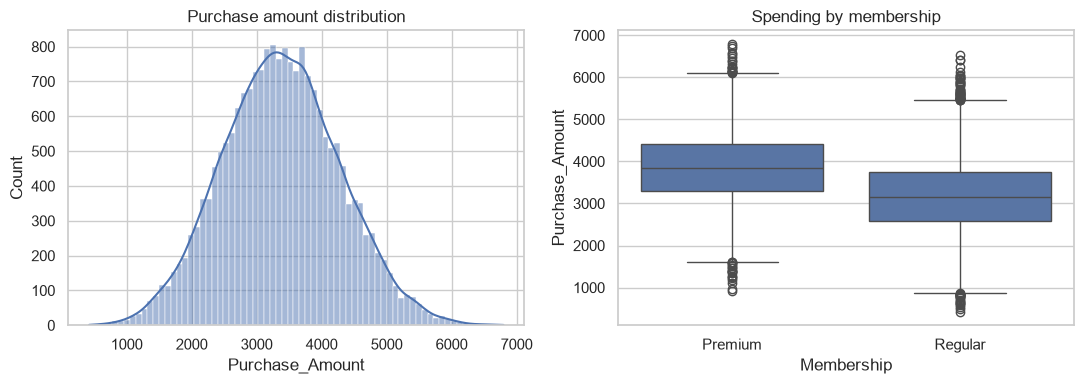


Sampling comparison:
  Population     n=20000 mean=3378.90
  Simple random  n= 4000 mean=3362.37
  Systematic     n= 4000 mean=3402.90
  Stratified     n= 4000 mean=3392.23

Welch t-test | H0: Premium and Regular mean spending are equal | H1: they differ
  Premium mean=3855.31, Regular mean=3169.59
  t=53.105, p=0, Cohen's d=0.814 -> Reject H0


In [3]:
head("TASK 2: DESCRIPTIVE AND INFERENTIAL STATISTICS")
desc = pd.DataFrame({"Mean":df[num].mean(),"Median":df[num].median(),"Mode":df[num].mode().iloc[0],
    "Variance":df[num].var(),"Std_Dev":df[num].std()})
print(desc.round(2).to_string())
y = df.Purchase_Amount
print(f"\nPurchase amount: skewness={y.skew():.3f}, kurtosis={y.kurt():.3f}")
fig, ax = plt.subplots(1,2,figsize=(11,4))
sns.histplot(y, kde=True, ax=ax[0]); ax[0].set_title("Purchase amount distribution")
sns.boxplot(data=df, x="Membership", y="Purchase_Amount", ax=ax[1]); ax[1].set_title("Spending by membership")
save("01_distribution.png")
samples = {"Population": df,
  "Simple random": df.sample(frac=0.2, random_state=1),
  "Systematic": df.iloc[np.random.default_rng(1).integers(0,5)::5],
  "Stratified": df.groupby("Membership").sample(frac=0.2, random_state=1)}
print("\nSampling comparison:")
for k,s in samples.items(): print(f"  {k:14s} n={len(s):5d} mean={s.Purchase_Amount.mean():.2f}")
a = df[df.Membership=="Premium"].Purchase_Amount; b = df[df.Membership=="Regular"].Purchase_Amount
t,p = stats.ttest_ind(a,b,equal_var=False)
d = (a.mean()-b.mean())/np.sqrt(((len(a)-1)*a.var()+(len(b)-1)*b.var())/(len(a)+len(b)-2))
print("\nWelch t-test | H0: Premium and Regular mean spending are equal | H1: they differ")
print(f"  Premium mean={a.mean():.2f}, Regular mean={b.mean():.2f}")
print(f"  t={t:.3f}, p={p:.3g}, Cohen's d={d:.3f} ->", "Reject H0" if p<0.05 else "Fail to reject H0")

## Task 3: Probability Analysis


TASK 3: PROBABILITY ANALYSIS
'High spender' = purchase above 4000; 'engaged' = more than 20 minutes on site
P(High) = 0.2420
P(High | Engaged) = 0.4598   P(High | Not engaged) = 0.1014

Bayes: probability that a high spender is a Premium member
  P(Premium)=0.3053, P(High|Premium)=0.4239, P(High|Regular)=0.1621, P(High)=0.2420
  P(Premium|High) = 0.5347   (direct count check: 0.5347)

Law of large numbers (random draws with replacement):
  n=   10  observed=0.3000  true=0.2420
  n=  100  observed=0.2000  true=0.2420
  n= 1000  observed=0.2470  true=0.2420
  n=10000  observed=0.2379  true=0.2420


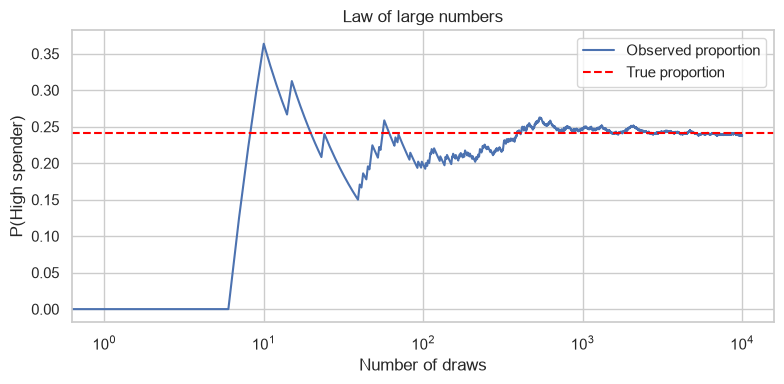

In [4]:
head("TASK 3: PROBABILITY ANALYSIS")
HIGH = round(float(y.quantile(0.75)), -2); T = 20
H = y > HIGH; E = df.Time_On_Site > T
print(f"'High spender' = purchase above {HIGH:.0f}; 'engaged' = more than {T} minutes on site")
print(f"P(High) = {H.mean():.4f}")
print(f"P(High | Engaged) = {H[E].mean():.4f}   P(High | Not engaged) = {H[~E].mean():.4f}")
P = df.Membership=="Premium"
pA, pBA, pBn = P.mean(), H[P].mean(), H[~P].mean()
pB = pBA*pA + pBn*(1-pA); post = pBA*pA/pB
print("\nBayes: probability that a high spender is a Premium member")
print(f"  P(Premium)={pA:.4f}, P(High|Premium)={pBA:.4f}, P(High|Regular)={pBn:.4f}, P(High)={pB:.4f}")
print(f"  P(Premium|High) = {post:.4f}   (direct count check: {P[H].mean():.4f})")
draws = np.random.default_rng(7).choice(H.astype(int), 10000, replace=True)
running = np.cumsum(draws)/np.arange(1,len(draws)+1)
print("\nLaw of large numbers (random draws with replacement):")
for k in [10,100,1000,10000]: print(f"  n={k:5d}  observed={running[k-1]:.4f}  true={H.mean():.4f}")
plt.figure(figsize=(8,4)); plt.plot(running,label="Observed proportion"); plt.axhline(H.mean(),c="red",ls="--",label="True proportion")
plt.xscale("log"); plt.xlabel("Number of draws"); plt.ylabel("P(High spender)"); plt.title("Law of large numbers"); plt.legend(); save("02_lln.png")

## Task 4: Correlation Analysis


TASK 4: CORRELATION ANALYSIS
                          Pearson  Spearman
Cart_Items                  0.727     0.713
Pages_Viewed                0.647     0.631
Time_On_Site                0.645     0.631
Visits_Per_Month            0.473     0.457
Previous_Purchase_Amount    0.414     0.401
Discount_Percent           -0.005    -0.005
Review_Rating              -0.004    -0.004
Age                         0.002     0.001
Strongest factors: Cart_Items, Pages_Viewed, Time_On_Site


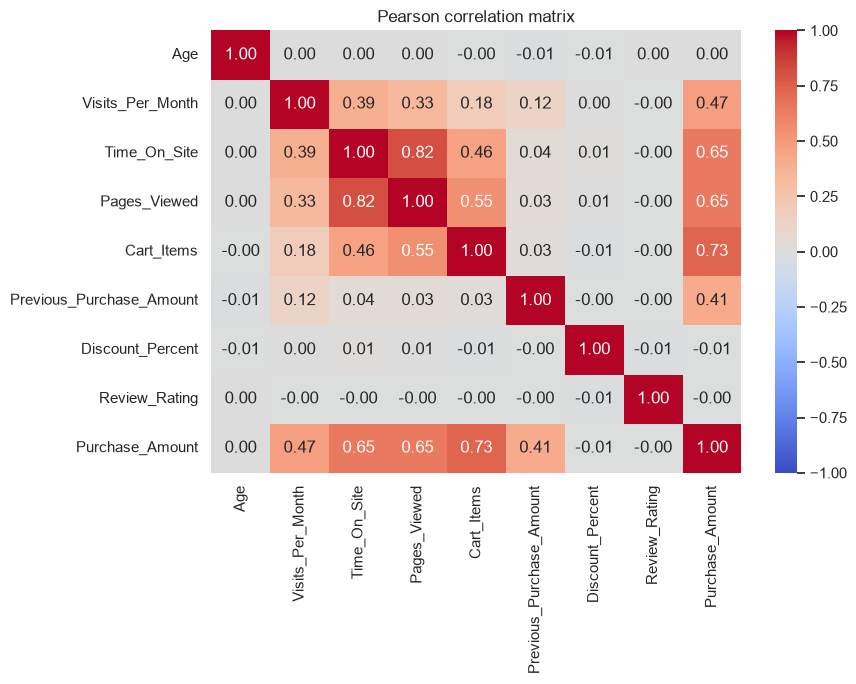

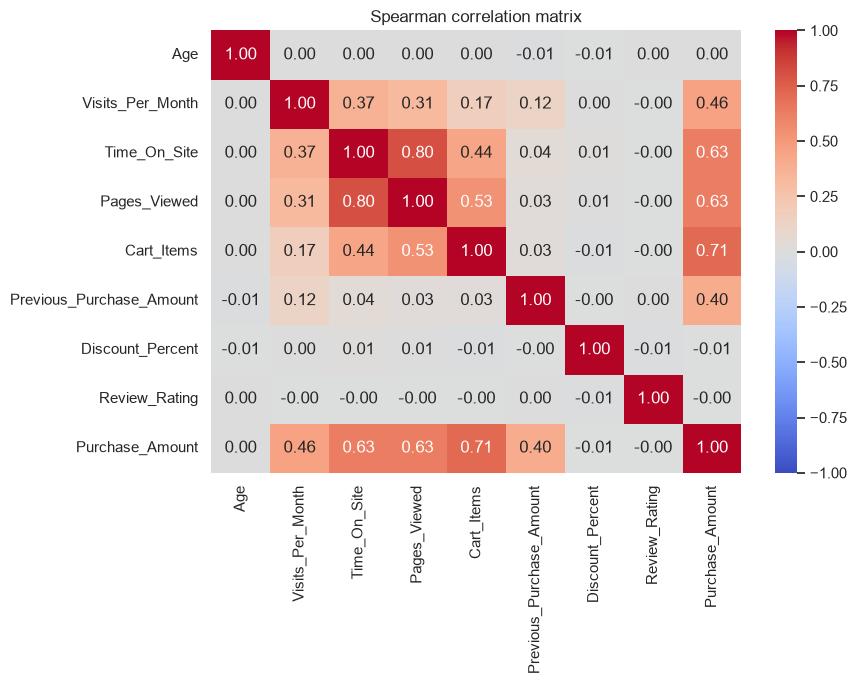

In [5]:
head("TASK 4: CORRELATION ANALYSIS")
pear = df[num].corr("pearson"); spear = df[num].corr("spearman")
ct = pd.DataFrame({"Pearson":pear.Purchase_Amount,"Spearman":spear.Purchase_Amount}).drop("Purchase_Amount")
ct = ct.sort_values("Pearson", key=abs, ascending=False)
print(ct.round(3).to_string()); print("Strongest factors:", ", ".join(ct.index[:3]))
for m,name in [(pear,"03_pearson.png"),(spear,"04_spearman.png")]:
    plt.figure(figsize=(9,7)); sns.heatmap(m,annot=True,fmt=".2f",cmap="coolwarm",vmin=-1,vmax=1)
    plt.title(name[3:-4].title()+" correlation matrix"); save(name)

## Task 5: Regression Analysis


TASK 5: REGRESSION ANALYSIS
Simple regression: intercept=1707.089
    Time_On_Site               90.1117
    test R2=0.4007 | 5-fold CV R2=0.4190 +/- 0.0114
Multiple regression: intercept=107.542
    Time_On_Site               32.6842
    Visits_Per_Month           45.2665
    Pages_Viewed               14.0873
    Cart_Items                 322.3887
    Previous_Purchase_Amount   0.3816
    test R2=0.8311 | 5-fold CV R2=0.8405 +/- 0.0022


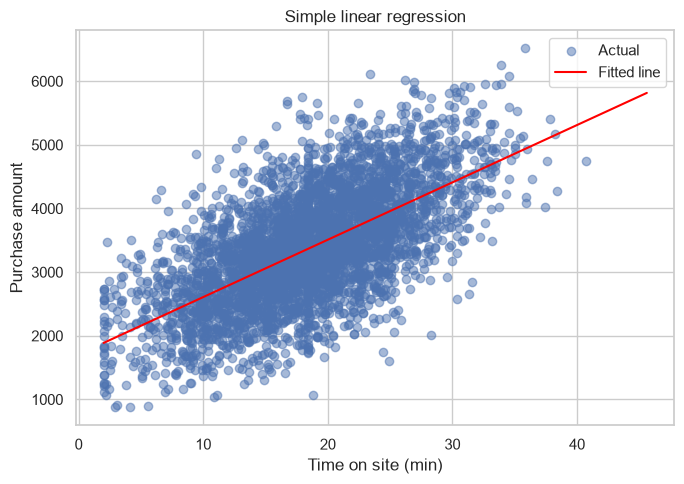

In [6]:
head("TASK 5: REGRESSION ANALYSIS")
simple_f = ["Time_On_Site"]
multi_f = ["Time_On_Site","Visits_Per_Month","Pages_Viewed","Cart_Items","Previous_Purchase_Amount"]
tr, te = df.loc[train_i], df.loc[test_i]; y_tr = tr.Purchase_Amount.values; y_te = te.Purchase_Amount.values
models = {}
for name,f in [("Simple",simple_f),("Multiple",multi_f)]:
    m = LinearRegression().fit(tr[f], y_tr); models[name] = (m, m.predict(te[f]))
    cv = cross_val_score(LinearRegression(), tr[f], y_tr, cv=KFold(5,shuffle=True,random_state=1), scoring="r2")
    print(f"{name} regression: intercept={m.intercept_:.3f}")
    for n_,c in zip(f,m.coef_): print(f"    {n_:26s} {c:.4f}")
    print(f"    test R2={m.score(te[f],y_te):.4f} | 5-fold CV R2={cv.mean():.4f} +/- {cv.std():.4f}")
plt.figure(figsize=(7,5)); plt.scatter(te.Time_On_Site,y_te,alpha=.5,label="Actual")
xs = pd.DataFrame({"Time_On_Site":np.linspace(df.Time_On_Site.min(),df.Time_On_Site.max(),100)})
plt.plot(xs,models["Simple"][0].predict(xs),c="red",label="Fitted line")
plt.xlabel("Time on site (min)"); plt.ylabel("Purchase amount"); plt.title("Simple linear regression"); plt.legend(); save("05_simple_regression.png")

## Task 6: Linear Algebra with NumPy

In [7]:
head("TASK 6: LINEAR ALGEBRA WITH NUMPY")
M = tr[multi_f].values.astype(float)
v1, v2 = M[0], M[1]
print("Customer vector 1:", v1); print("Customer vector 2:", v2)
print("Data matrix shape:", M.shape)
print("Matrix addition (first 2 rows + next 2 rows):\n", M[:2]+M[2:4])
print("Dot product v1.v2 =", round(float(np.dot(v1,v2)),2))
print("Matrix multiplication X(3x5) @ X^T(5x3):\n", (M[:3]@M[:3].T).round(1))
X = np.column_stack([np.ones(len(M)), M])
theta = np.linalg.solve(X.T@X, X.T@y_tr)
print("\nNormal equation  theta = (X^T X)^-1 X^T y")
print("  NumPy  :", theta.round(4))
m = models["Multiple"][0]; print("  sklearn:", np.r_[m.intercept_, m.coef_].round(4))
print("  First prediction as dot product:", round(float(X[0]@theta),2))


TASK 6: LINEAR ALGEBRA WITH NUMPY
Customer vector 1: [  24.3   17.    20.     3.  1333.8]
Customer vector 2: [  10.3    14.     11.      4.   2479.06]
Data matrix shape: (16000, 5)
Matrix addition (first 2 rows + next 2 rows):
 [[  46.8    31.     38.      8.   3716.03]
 [  25.4    30.     24.      9.   6405.68]]
Dot product v1.v2 = 3307290.52
Matrix multiplication X(3x5) @ X^T(5x3):
 [[1780310.9 3307290.5 3178578.1]
 [3307290.5 6146177.6 5906336.9]
 [3178578.1 5906336.9 5676071. ]]

Normal equation  theta = (X^T X)^-1 X^T y
  NumPy  : [107.5417  32.6842  45.2665  14.0873 322.3887   0.3816]
  sklearn: [107.5417  32.6842  45.2665  14.0873 322.3887   0.3816]
  First prediction as dot product: 3429.15


## Task 7: Calculus and Gradient Descent


TASK 7: CALCULUS AND GRADIENT DESCENT
Cost      J(theta) = (1/2m) * sum((X.theta - y)^2)
Gradient  dJ/dtheta = (1/m) * X^T (X.theta - y)
Update    theta = theta - alpha * gradient
iter    0  cost=    6103574.26  theta=[0. 0. 0. 0. 0. 0.]
iter    1  cost=    5480155.95  theta=[168.76  29.24  21.33  29.31  32.97  18.84]
iter   10  cost=    2158283.10  theta=[1354.38  164.86  128.92  163.17  216.84  142.55]
iter   50  cost=     100869.91  theta=[3115.57  186.59  185.44  159.89  404.52  304.39]
iter  100  cost=      65397.12  theta=[3355.3   182.33  191.08  121.86  452.6   324.58]
iter  500  cost=      64852.22  theta=[3375.28  210.89  191.96   77.56  472.4   325.6 ]
iter 1000  cost=      64851.95  theta=[3375.28  212.08  191.85   76.29  472.61  325.59]
GD parameters (original units): [107.5483  32.6817  45.2668  14.0906 322.3868   0.3816]
Max difference from normal equation: 6.58e-03


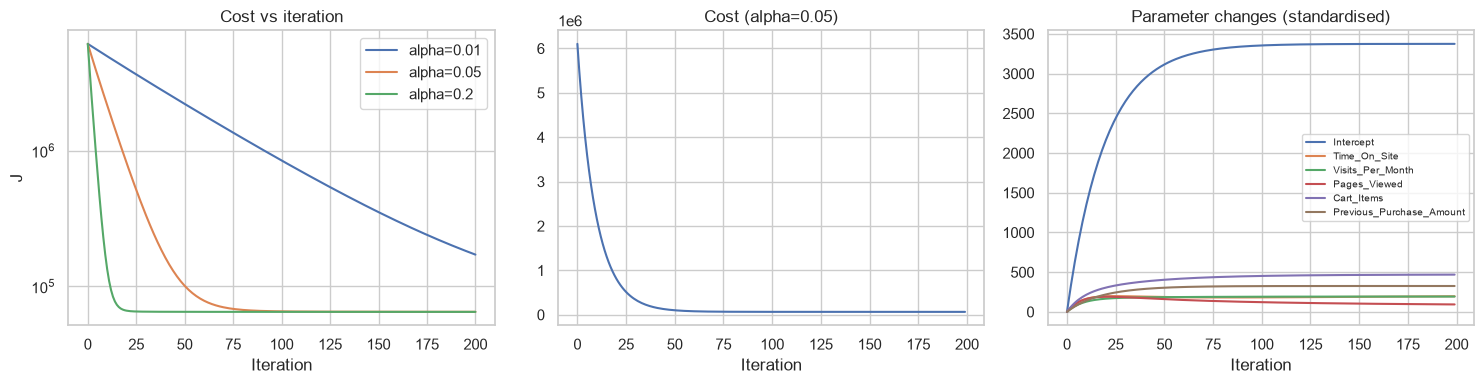

In [8]:
head("TASK 7: CALCULUS AND GRADIENT DESCENT")
print("Cost      J(theta) = (1/2m) * sum((X.theta - y)^2)")
print("Gradient  dJ/dtheta = (1/m) * X^T (X.theta - y)")
print("Update    theta = theta - alpha * gradient")
mu, sd = M.mean(0), M.std(0)
Z = np.column_stack([np.ones(len(M)), (M-mu)/sd])
cost = lambda w: np.sum((Z@w-y_tr)**2)/(2*len(y_tr))
def descend(alpha, iters):
    w = np.zeros(Z.shape[1]); hist=[w.copy()]; J=[cost(w)]
    for _ in range(iters):
        w = w - alpha*(Z.T@(Z@w-y_tr))/len(y_tr); hist.append(w.copy()); J.append(cost(w))
    return w, np.array(hist), J
w, hist, J = descend(0.05, 1000)
for k in [0,1,10,50,100,500,1000]: print(f"iter {k:4d}  cost={J[k]:14.2f}  theta={hist[k].round(2)}")
orig = np.r_[w[0]-np.sum(w[1:]*mu/sd), w[1:]/sd]
print("GD parameters (original units):", orig.round(4)); print("Max difference from normal equation:", f"{np.abs(orig-theta).max():.2e}")
fig, ax = plt.subplots(1,3,figsize=(15,4))
for al in [0.01,0.05,0.2]: ax[0].plot(descend(al,200)[2],label=f"alpha={al}")
ax[0].set(title="Cost vs iteration",xlabel="Iteration",ylabel="J"); ax[0].set_yscale("log"); ax[0].legend()
ax[1].plot(J[:200]); ax[1].set(title="Cost (alpha=0.05)",xlabel="Iteration")
for i,n_ in enumerate(["Intercept"]+multi_f): ax[2].plot(hist[:200,i],label=n_)
ax[2].set(title="Parameter changes (standardised)",xlabel="Iteration"); ax[2].legend(fontsize=7); save("06_gradient_descent.png")

## Task 8: Model Evaluation and Residual Analysis


TASK 8: MODEL EVALUATION AND RESIDUAL ANALYSIS
                       MAE          MSE      RMSE      R2
Simple            549.2525  473666.6324  688.2344  0.4007
Multiple          293.6465  133472.7464  365.3392  0.8311
Gradient descent  293.6465  133472.6887  365.3391  0.8311

Actual vs predicted (first 10):
 Customer_ID  Actual  Predicted  Residual         Status
     C11025 3084.09    2993.99     90.10 Underestimated
     C18598 1846.51    1429.23    417.28 Underestimated
     C11087 3373.36    3357.18     16.18 Underestimated
     C13382 3703.86    3265.79    438.07 Underestimated
     C07506 3804.92    3583.94    220.98 Underestimated
     C13337 3499.04    3535.34    -36.30  Overestimated
     C13139 2866.63    2707.84    158.79 Underestimated
     C02226 3141.32    2433.62    707.70 Underestimated
     C18640 1884.54    1865.80     18.74 Underestimated
     C18965 3254.33    3339.89    -85.56  Overestimated

Residual = Actual - Predicted (negative means overestimate)
Mean resi

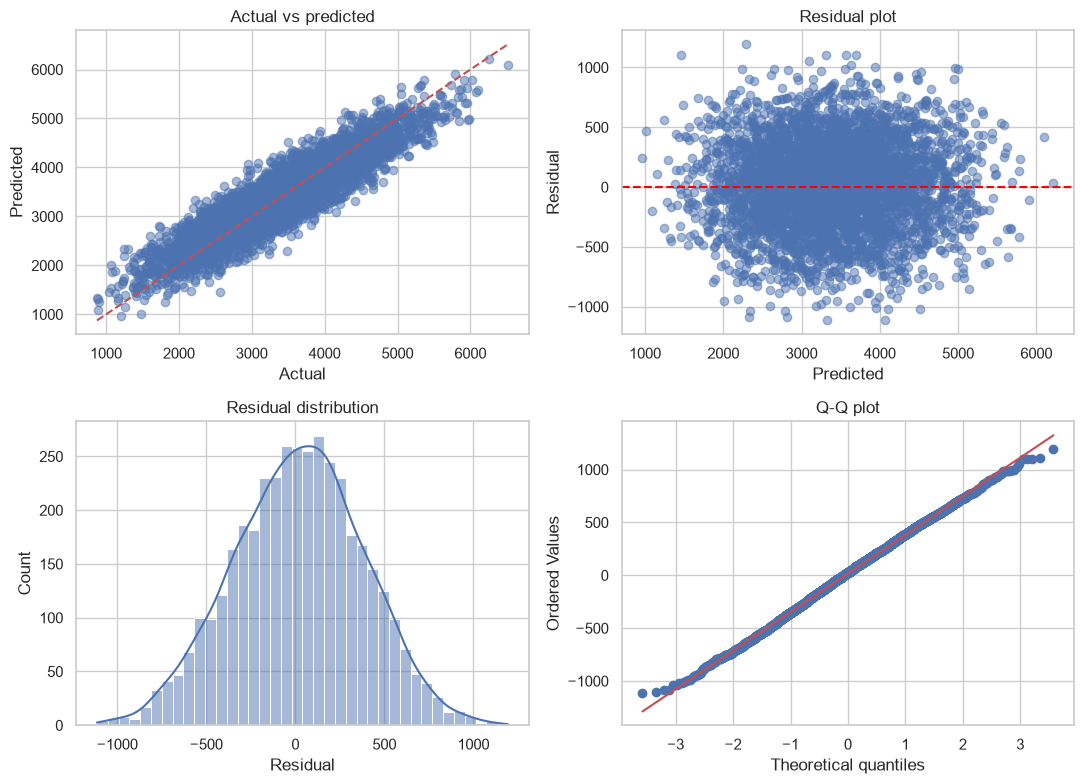


DONE. Files: CSVs in this folder, charts in plots/


In [9]:
head("TASK 8: MODEL EVALUATION AND RESIDUAL ANALYSIS")
Zte = np.column_stack([np.ones(len(te)), (te[multi_f].values-mu)/sd])
preds = {"Simple":models["Simple"][1], "Multiple":models["Multiple"][1], "Gradient descent":Zte@w}
rows = {}
for n_,pr in preds.items():
    res = y_te-pr; mse = np.mean(res**2)
    rows[n_] = dict(MAE=np.mean(np.abs(res)), MSE=mse, RMSE=np.sqrt(mse), R2=1-np.sum(res**2)/np.sum((y_te-y_te.mean())**2))
metrics = pd.DataFrame(rows).T; print(metrics.round(4).to_string()); metrics.to_csv("model_metrics.csv")
comp = pd.DataFrame({"Customer_ID":te.Customer_ID,"Actual":y_te,"Predicted":preds["Multiple"].round(2)})
comp["Residual"] = (comp.Actual-comp.Predicted).round(2)
comp["Status"] = np.where(comp.Residual<0,"Overestimated","Underestimated")
comp.to_csv("predictions.csv", index=False)
print("\nActual vs predicted (first 10):\n", comp.head(10).to_string(index=False))
print("\nResidual = Actual - Predicted (negative means overestimate)")
print(f"Mean residual = {comp.Residual.mean():.2f}"); print(comp.Status.value_counts().to_string())
bands = pd.qcut(comp.Actual,3,labels=["Low","Medium","High"])
print("\nMean residual by actual spending band:\n", comp.groupby(bands,observed=True).Residual.mean().round(2).to_string())
print(f"Shapiro-Wilk p-value for residuals = {stats.shapiro(comp.Residual).pvalue:.4f}")
fig, ax = plt.subplots(2,2,figsize=(11,8))
ax[0,0].scatter(comp.Actual,comp.Predicted,alpha=.5); lim=[comp.Actual.min(),comp.Actual.max()]
ax[0,0].plot(lim,lim,"r--"); ax[0,0].set(title="Actual vs predicted",xlabel="Actual",ylabel="Predicted")
ax[0,1].scatter(comp.Predicted,comp.Residual,alpha=.5); ax[0,1].axhline(0,c="red",ls="--"); ax[0,1].set(title="Residual plot",xlabel="Predicted",ylabel="Residual")
sns.histplot(comp.Residual,kde=True,ax=ax[1,0]); ax[1,0].set_title("Residual distribution")
stats.probplot(comp.Residual,plot=ax[1,1]); ax[1,1].set_title("Q-Q plot"); save("07_residuals.png")
print("\nDONE. Files: CSVs in this folder, charts in plots/")